In [1]:

from google.colab import files

uploaded = files.upload()


Saving Mall_Customers.csv to Mall_Customers.csv


In [2]:

import pandas as pd

df = pd.read_csv("Mall_Customers.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:

# Check column names, data types, and non-null values
df.info()

# Check missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing values:
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0


In [4]:

# Generate summary statistics
df.describe()


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


Genre
Female    112
Male       88
Name: count, dtype: int64


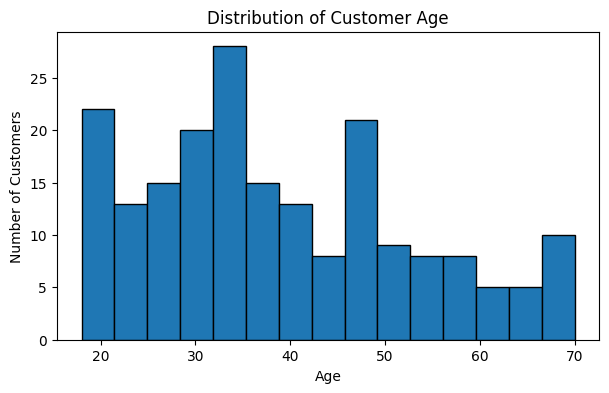

In [5]:

# Check the number of customers by genre
print(df["Genre"].value_counts())

# Visualize the distribution of customer ages
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.hist(df["Age"], bins=15, edgecolor="black")
plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()


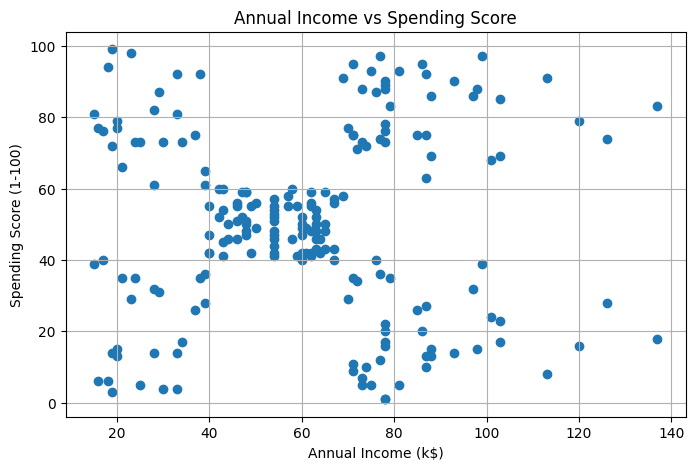

In [6]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"]
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.grid(True)
plt.show()


In [7]:

# Select features for customer segmentation
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# Display the first five rows
X.head()


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [8]:

from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Scale the selected features
X_scaled = scaler.fit_transform(X)

# Display the first five scaled rows
print(X_scaled[:5])


[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


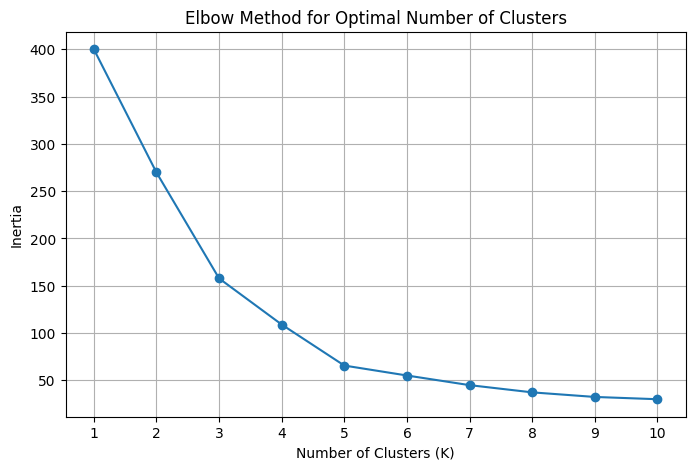

In [9]:

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

# Test between 1 and 10 clusters
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


In [10]:

from sklearn.metrics import silhouette_score

# Test different numbers of clusters
for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    print(f"K = {k}, Silhouette Score = {score:.4f}")


K = 2, Silhouette Score = 0.3213
K = 3, Silhouette Score = 0.4666
K = 4, Silhouette Score = 0.4939
K = 5, Silhouette Score = 0.5547
K = 6, Silhouette Score = 0.5399
K = 7, Silhouette Score = 0.5281
K = 8, Silhouette Score = 0.4552
K = 9, Silhouette Score = 0.4571
K = 10, Silhouette Score = 0.4432


In [11]:

# Build the final K-Means model
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Assign a cluster to each customer
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Display the first 10 customers with their clusters
df.head(10)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


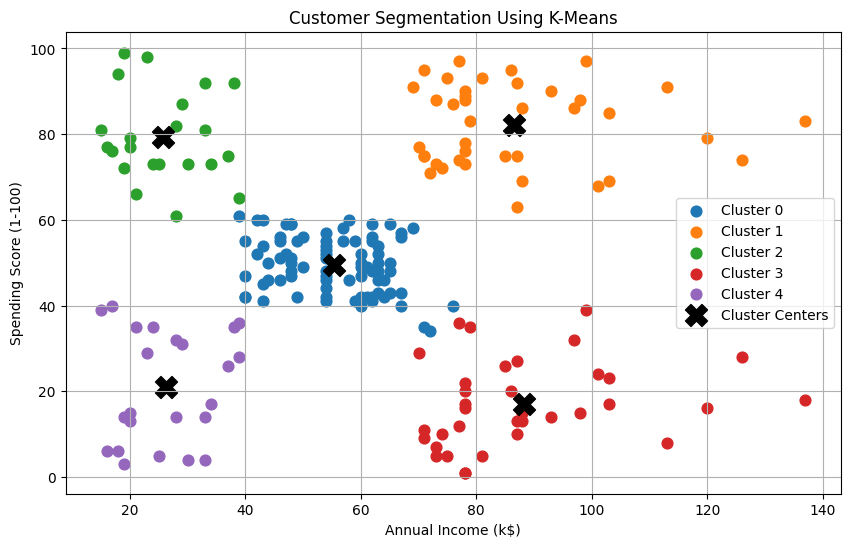

In [12]:

import matplotlib.pyplot as plt

# Get the cluster centers and convert them to original units
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(10, 6))

# Plot customers in each cluster
for cluster in range(5):
    cluster_data = df[df["Cluster"] == cluster]

    plt.scatter(
        cluster_data["Annual Income (k$)"],
        cluster_data["Spending Score (1-100)"],
        label=f"Cluster {cluster}",
        s=60
    )

# Plot cluster centers
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Cluster Centers"
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(True)
plt.show()


In [13]:

# Calculate customer statistics for each cluster
cluster_summary = df.groupby("Cluster").agg(
    Number_of_Customers=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

cluster_summary


,Number_of_Customers,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


In [14]:

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce the scaled data to 2 principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Check how much variance the components explain
print("Explained variance ratio:", pca.explained_variance_ratio_)
print(
    "Total variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


Explained variance ratio: [0.50495142 0.49504858]
Total variance explained: 100.0 %


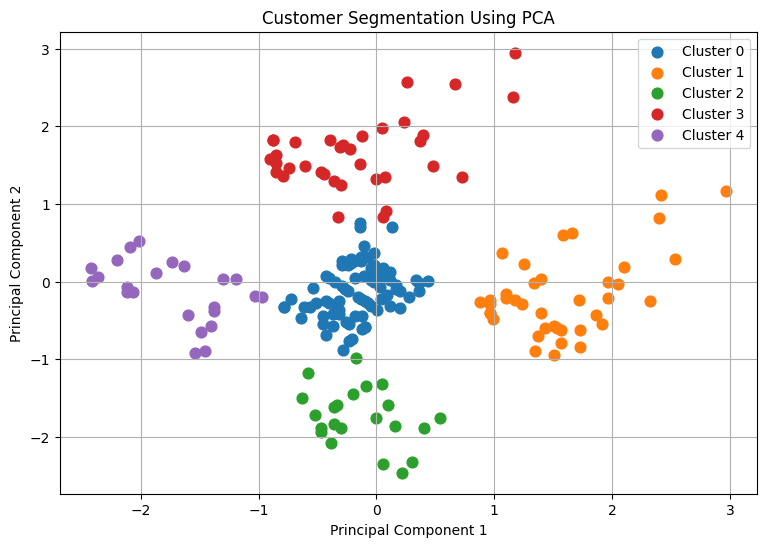

In [16]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for cluster in range(5):
    mask = df["Cluster"].to_numpy() == cluster

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cluster}",
        s=60
    )

plt.title("Customer Segmentation Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True)
plt.show()


In [17]:

print("CUSTOMER SEGMENTATION PROJECT SUMMARY")
print("-" * 45)

print("Total customers:", len(df))
print("Number of clusters:", df["Cluster"].nunique())
print("Best Silhouette Score: 0.5547")
print("PCA variance explained: 100.0%")

print("\nCUSTOMER CLUSTER SUMMARY")
display(cluster_summary)

print("\nCUSTOMER PERSONAS")

personas = {
    0: "Middle-income, regular spenders",
    1: "High-income, high spenders",
    2: "Low-income, high spenders",
    3: "High-income, low spenders",
    4: "Low-income, low spenders"
}

for cluster, persona in personas.items():
    print(f"Cluster {cluster}: {persona}")


CUSTOMER SEGMENTATION PROJECT SUMMARY
---------------------------------------------
Total customers: 200
Number of clusters: 5
Best Silhouette Score: 0.5547
PCA variance explained: 100.0%

CUSTOMER CLUSTER SUMMARY


,Number_of_Customers,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91



CUSTOMER PERSONAS
Cluster 0: Middle-income, regular spenders
Cluster 1: High-income, high spenders
Cluster 2: Low-income, high spenders
Cluster 3: High-income, low spenders
Cluster 4: Low-income, low spenders


In [18]:

# STEP 18: BUSINESS INSIGHTS AND RECOMMENDATIONS

print("=" * 65)
print("CUSTOMER SEGMENTATION: BUSINESS INSIGHTS & RECOMMENDATIONS")
print("=" * 65)

recommendations = {
    0: {
        "Persona": "Middle-Income, Regular Spenders",
        "Insight": "Largest segment with 81 customers.",
        "Strategy": "Offer loyalty rewards, bundle deals, and personalized offers."
    },
    1: {
        "Persona": "High-Income, High Spenders",
        "Insight": "Customers with high income and high spending scores.",
        "Strategy": "Provide premium products, VIP memberships, and exclusive offers."
    },
    2: {
        "Persona": "Low-Income, High Spenders",
        "Insight": "Customers who spend actively despite lower average income.",
        "Strategy": "Offer affordable premium options, flexible deals, and reward points."
    },
    3: {
        "Persona": "High-Income, Low Spenders",
        "Insight": "Higher-income customers with lower spending scores.",
        "Strategy": "Use personalized recommendations, product demonstrations, and targeted campaigns."
    },
    4: {
        "Persona": "Low-Income, Low Spenders",
        "Insight": "Customers with lower average income and spending scores.",
        "Strategy": "Offer budget-friendly products, discounts, and value bundles."
    }
}

for cluster, details in recommendations.items():
    print(f"\nCLUSTER {cluster}: {details['Persona']}")
    print(f"Business Insight: {details['Insight']}")
    print(f"Recommendation: {details['Strategy']}")

print("\n" + "=" * 65)
print("KEY BUSINESS TAKEAWAY")
print("=" * 65)
print(
    "Customer segmentation helps businesses personalize marketing, "
    "improve customer engagement, and allocate marketing budgets "
    "more effectively."
)


CUSTOMER SEGMENTATION: BUSINESS INSIGHTS & RECOMMENDATIONS

CLUSTER 0: Middle-Income, Regular Spenders
Business Insight: Largest segment with 81 customers.
Recommendation: Offer loyalty rewards, bundle deals, and personalized offers.

CLUSTER 1: High-Income, High Spenders
Business Insight: Customers with high income and high spending scores.
Recommendation: Provide premium products, VIP memberships, and exclusive offers.

CLUSTER 2: Low-Income, High Spenders
Business Insight: Customers who spend actively despite lower average income.
Recommendation: Offer affordable premium options, flexible deals, and reward points.

CLUSTER 3: High-Income, Low Spenders
Business Insight: Higher-income customers with lower spending scores.
Recommendation: Use personalized recommendations, product demonstrations, and targeted campaigns.

CLUSTER 4: Low-Income, Low Spenders
Business Insight: Customers with lower average income and spending scores.
Recommendation: Offer budget-friendly products, discounts

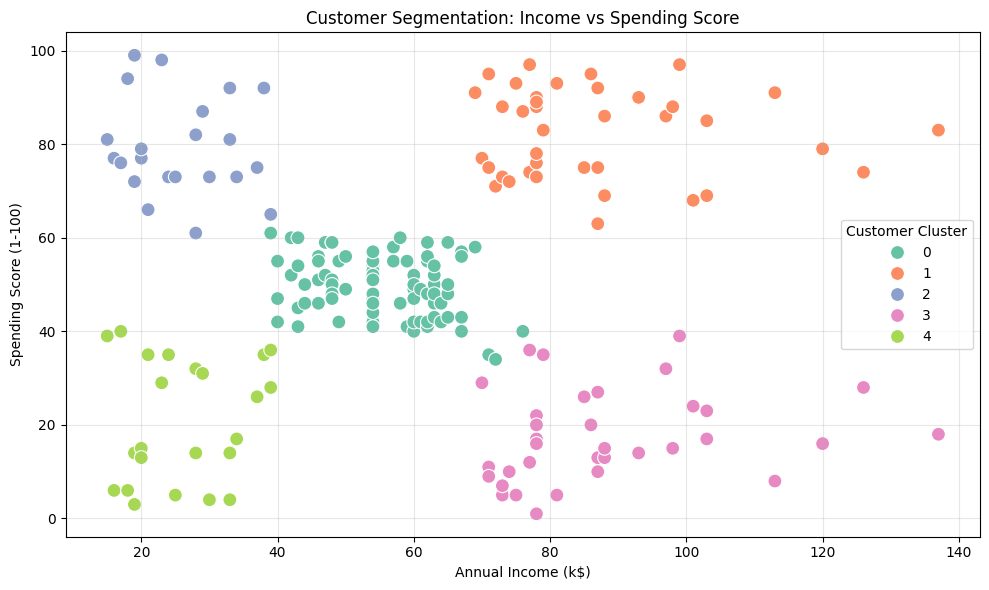

In [19]:

# STEP 19: VISUALIZE CUSTOMER SEGMENTS

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='Set2',
    s=100
)

plt.title('Customer Segmentation: Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Customer Cluster')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


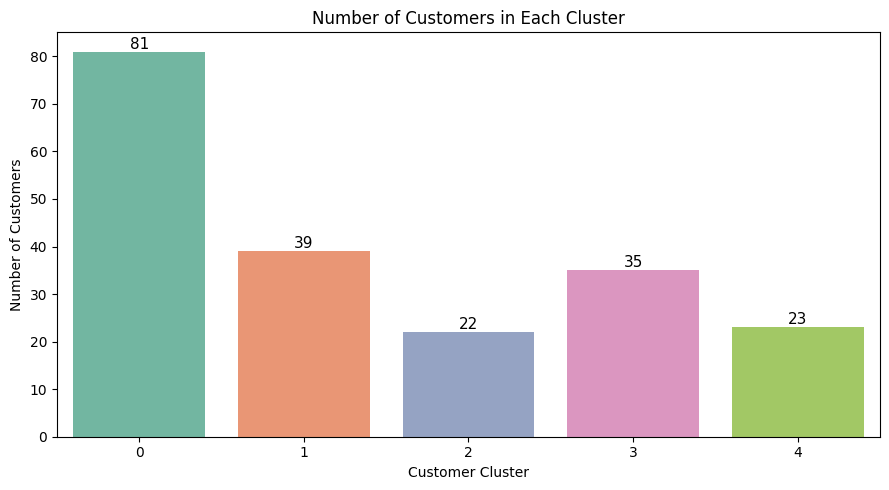

Customer count in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [20]:

# STEP 20: CUSTOMER CLUSTER SIZE COMPARISON

import matplotlib.pyplot as plt
import seaborn as sns

cluster_counts = df['Cluster'].value_counts().sort_index()

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=cluster_counts.index.astype(str),
    y=cluster_counts.values,
    hue=cluster_counts.index.astype(str),
    palette='Set2',
    legend=False
)

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f'{int(height)}',
        (bar.get_x() + bar.get_width() / 2, height),
        ha='center',
        va='bottom',
        fontsize=11
    )

plt.title('Number of Customers in Each Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

print("Customer count in each cluster:")
print(cluster_counts)


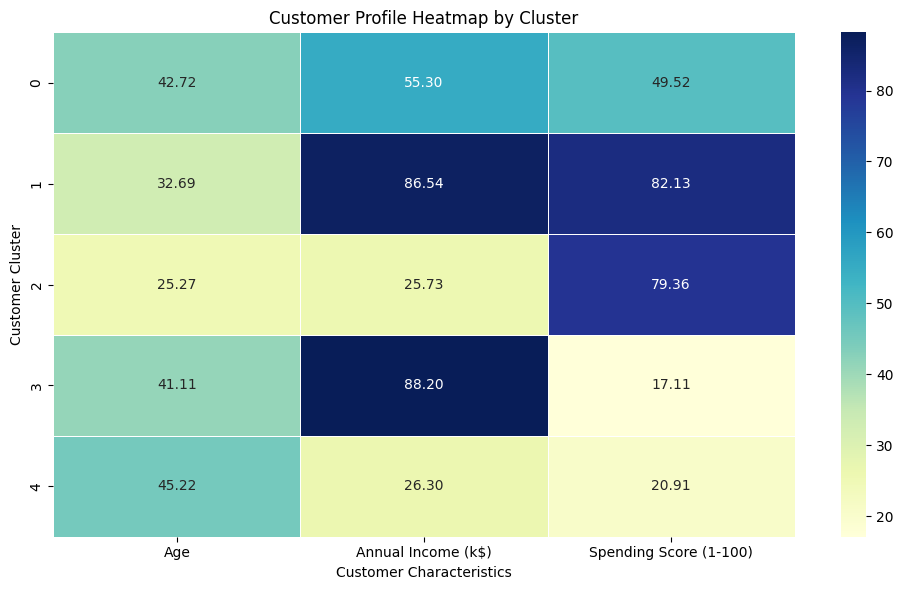

Average customer profile by cluster:


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,42.72,55.30,49.52
1,32.69,86.54,82.13
2,25.27,25.73,79.36
3,41.11,88.20,17.11
4,45.22,26.30,20.91


In [21]:

# STEP 21: CUSTOMER PROFILE HEATMAP

import matplotlib.pyplot as plt
import seaborn as sns

cluster_profile = df.groupby('Cluster')[
    ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
].mean()

plt.figure(figsize=(10, 6))

sns.heatmap(
    cluster_profile,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('Customer Profile Heatmap by Cluster')
plt.xlabel('Customer Characteristics')
plt.ylabel('Customer Cluster')
plt.tight_layout()
plt.show()

print("Average customer profile by cluster:")
display(cluster_profile.round(2))


# Conclusion — Customer Segmentation Using Machine Learning

This project used customer demographic and behavioral data to identify distinct customer segments through clustering.

## Key Results
- Analyzed 200 customers.
- Identified 5 customer segments.
- Achieved a best Silhouette Score of 0.5547, indicating reasonable separation between clusters.
- Used PCA for dimensionality reduction and visualization.
- Created customer personas and actionable business recommendations.

## Business Impact
The five segments represent middle-income regular spenders, high-income high spenders, low-income high spenders, high-income low spenders, and low-income low spenders.

Businesses can use these insights to personalize marketing campaigns, design loyalty programs, recommend suitable products, and improve customer engagement.

## Conclusion
Customer segmentation demonstrates how unsupervised machine learning can transform customer data into meaningful business insights. The results provide a foundation for data-driven marketing strategies and more personalized customer experiences.